# 2.11b — Opérateurs proximaux : ISTA et FISTA

[Source Python](2.11b-Proximal-Operators-From-Scratch.ipynb) | [Index du cours](README.md)

**Objectifs** : dériver le proximal L1, implémenter ISTA et FISTA, lire une expérience de reconstruction parcimonieuse, puis comparer les objectifs, supports et trajectoires à scikit-learn et CVXPY. **Prérequis** : calcul matriciel, convexité et Lasso. **Durée indicative** : 90 minutes.

Nous étudions `F(x)=f(x)+g(x)` lorsque `f` a un gradient lisse et `g` peut être non lisse. L'instance est `f(x)=½‖Ax−b‖²`, `g(x)=λ‖x‖₁`. Les algorithmes sont écrits en C# avec MathNet ; NumPy fournit le même tirage que le carnet Python, et Python.NET appelle les vrais `sklearn.linear_model.Lasso` et `cvxpy`/CLARABEL pour les références.

### Environnement Python.NET

Installer NumPy, SciPy, scikit-learn et CVXPY avec CLARABEL dans un environnement CPython compatible avec Python.NET. Définir `PYTHONNET_PYDLL` vers la bibliothèque partagée de **cette version** de CPython. S'assurer que son répertoire standard et les `site-packages` contenant ces bibliothèques sont visibles du processus .NET : selon l'installation, configurer `PYTHONHOME` vers le préfixe CPython et `PYTHONPATH` vers le `site-packages` de l'environnement. Le chemin de la bibliothèque seul ne sélectionne pas nécessairement un venv. Sous Windows la bibliothèque est une DLL ; sous Linux/macOS c'est une bibliothèque partagée `.so`/`.dylib`. Vérifier les imports dans cet environnement avant d'exécuter le carnet.

**Navigation** : [Parent : régularisation](2.11-Regularisation-Sparse-LASSO.ipynb) | [Version Python de cette étape](2.11b-Proximal-Operators-From-Scratch.ipynb) | [Suivant : 2.11c](2.11c-Lasso-SOTA-Comparison.ipynb) | [Index](README.md)


In [3]:
#r "nuget: MathNet.Numerics, 5.0.0"
#r "nuget: pythonnet, 3.1.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Diagnostics;
using System.Text;
using System.Text.Json;
using MathNet.Numerics.LinearAlgebra;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
// Le pont charge le CPython configuré une seule fois ; les calculs proximaux restent en C#.
if (!PythonEngine.IsInitialized)
{
    var library = Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (string.IsNullOrWhiteSpace(library))
        throw new InvalidOperationException("Définir PYTHONNET_PYDLL vers CPython et installer NumPy, scikit-learn et CVXPY.");
    Runtime.PythonDLL = library;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}
string PythonResult(string source)
{
    using (Py.GIL())
    using (var scope = Py.CreateScope())
    {
        scope.Exec(source);
        return scope.Get("result").As<string>();
    }
}
var V = Vector<double>.Build;
var Mat = Matrix<double>.Build;
Vector<double> ArrayVector(JsonElement array) => V.DenseOfEnumerable(array.EnumerateArray().Select(x => x.GetDouble()));
Matrix<double> ArrayMatrix(JsonElement array) => Mat.DenseOfRowArrays(array.EnumerateArray().Select(row => row.EnumerateArray().Select(x => x.GetDouble()).ToArray()).ToArray());
// Le proximal L1 met exactement à zéro les composantes dans la zone morte.
Vector<double> Shrink(Vector<double> x, double threshold) => x.Map(v => Math.Sign(v) * Math.Max(Math.Abs(v) - threshold, 0.0));
double Objective(Matrix<double> a, Vector<double> b, Vector<double> x, double lambda)
{
    var residual = a * x - b;
    return 0.5 * residual.DotProduct(residual) + lambda * x.L1Norm();
}
Console.WriteLine("MathNet et Python.NET initialisés ; références Python chargées au besoin.");

Installing Packages MathNet.Numerics pythonnet

MathNet et Python.NET initialisés ; références Python chargées au besoin.


## 1. Proximal L1 : le seuillage doux

Pour un vecteur d'entrée `v`, le proximal de `τ‖·‖₁` est séparable :

`prox_{τ‖·‖₁}(v)_i = sign(v_i) max(|v_i|−τ, 0)`.

La condition de sous-gradient `0 ∈ x−v+τ∂‖x‖₁` explique les trois régimes : au-delà du seuil on conserve le signe et retranche τ au module ; à l'intérieur de la zone morte on obtient exactement zéro. L'opérateur est continu et non expansif. Ici τ désigne le **paramètre du proximal** : dans ISTA/FISTA il vaut `λ/L`, alors que λ est le coefficient de l'objectif. Le proximal s'applique au point obtenu après gradient, pas directement aux coefficients vrais du signal.

## 2. ISTA — gradient puis proximal

Pour `F=f+g`, avec `f(x)=½‖Ax−b‖²` et `g(x)=λ‖x‖₁`, le gradient est `∇f(x)=Aᵀ(Ax−b)`. Sa constante de Lipschitz est `L=‖A‖²₂=σ_max(A)²`, calculée ici par SVD. ISTA utilise

`x_{k+1}=prox_{g/L}(x_k−∇f(x_k)/L)`.

On part de `x₀=0` et l'on enregistre l'objectif composite après chaque pas. Le code s'arrête quand `‖x_{k+1}−x_k‖∞ < tol(1+‖x_k‖∞)` ou au plafond choisi. Sous les hypothèses convexes et lisses usuelles, l'écart d'objectif composite admet une borne `O(1/k)`.

## 3. FISTA — extrapolation après le pas proximal

FISTA conserve le même L et initialise `y₀=x₀=0`, `t₀=1`. Il effectue les opérations dans cet ordre :

```
x_{k+1}=prox_{g/L}(y_k−∇f(y_k)/L)
t_{k+1}=(1+sqrt(1+4t_k²))/2
y_{k+1}=x_{k+1}+((t_k−1)/t_{k+1})(x_{k+1}−x_k)
```

Le garde d'arrêt utilise la même variation entre itérés que pour ISTA. Sous les mêmes hypothèses adaptées à FISTA, la borne en écart d'objectif composite est `O(1/k²)`. Ce taux ne garantit ni la monotonie de chaque itéré ni un facteur de temps fixe.

In [4]:
Console.WriteLine($"S0(0.5)={Shrink(V.DenseOfArray(new[]{0.5}),0)[0]}");
Console.WriteLine($"S1(-0.3)={Shrink(V.DenseOfArray(new[]{-0.3}),1)[0]}");
Console.WriteLine($"S1(2)={Shrink(V.DenseOfArray(new[]{2.0}),1)[0]}, S1(-2)={Shrink(V.DenseOfArray(new[]{-2.0}),1)[0]}");
(Vector<double> x, double[] history) Proximal(Matrix<double> a, Vector<double> b, double lambda, int maxIter, double tolerance, bool accelerated)
{
    // La plus grande valeur singulière fixe un pas valable pour le gradient de la perte.
    double lipschitz = Math.Pow(a.Svd(false).S[0], 2);
    double step = 1.0 / lipschitz;
    var x = V.Dense(a.ColumnCount);
    var y = x.Clone();
    var at = a.Transpose();
    var atb = at * b;
    var history = new List<double>();
    double t = 1.0;
    for (int iteration = 0; iteration < maxIter; iteration++)
    {
        var origin = accelerated ? y : x;
        // FISTA évalue le gradient au point extrapolé, ISTA à l’itéré courant.
        var gradient = at * (a * origin) - atb;
        var next = Shrink(origin - step * gradient, lambda * step);
        double nextT = (1.0 + Math.Sqrt(1.0 + 4.0 * t * t)) / 2.0;
        if (accelerated)
            y = next + ((t - 1.0) / nextT) * (next - x);
        double delta = (next - x).InfinityNorm();
        double limit = tolerance * (1.0 + x.InfinityNorm());
        x = next;
        history.Add(Objective(a, b, x, lambda));
        if (delta < limit) break;
        t = nextT;
    }
    return (x, history.ToArray());
}
Console.WriteLine("ISTA et FISTA définis avec arrêt relatif et SVD MathNet.");

S0(0.5)=0.5


S1(-0.3)=-0


S1(2)=1, S1(-2)=-1


ISTA et FISTA définis avec arrêt relatif et SVD MathNet.


### Exercice 1 — Proximal matriciel

Implémenter `ExerciceProx` pour appliquer le seuillage doux à chaque entrée d'une matrice, en préservant ses dimensions. Tester seuil nul, zone morte et survivants positifs et négatifs. Le garde contrôle les résultats sur plusieurs matrices ; il n'impose pas une forme particulière de boucle.

In [5]:
Matrix<double> ExerciceProx(Matrix<double> value, double threshold)
{
    // TODO : appliquer le seuillage à chaque élément, sans modifier la forme.
    return null;
}
var fixtures = new[]
{
    (Mat.DenseOfArray(new double[,] {{.5,-.2,1.5},{-.3,0,2}}), .5,
     Mat.DenseOfArray(new double[,] {{0,0,1},{0,0,1.5}})),
    (Mat.DenseOfArray(new double[,] {{-3,-1,0},{.25,1.5,4}}), 1.0,
     Mat.DenseOfArray(new double[,] {{-2,0,0},{0,.5,3}})),
    (Mat.DenseOfArray(new double[,] {{-.4,.7}}), 0.0,
     Mat.DenseOfArray(new double[,] {{-.4,.7}}))
};
var answers = fixtures.Select(f => ExerciceProx(f.Item1,f.Item2)).ToArray();
if (answers.All(a => a == null))
{
    Console.WriteLine("Exercice 1 à compléter.");
}
else if (answers.Any(a => a == null))
{
    Console.WriteLine("Exercice 1 : à revoir");
}
else
{
    bool ok = true;
    for (int i=0; i<fixtures.Length; i++)
    {
        var expected=fixtures[i].Item3;
        var answer=answers[i];
        ok = ok && answer.RowCount==expected.RowCount && answer.ColumnCount==expected.ColumnCount &&
             answer.Enumerate().All(double.IsFinite) && (answer-expected).FrobeniusNorm()<1e-10;
    }
    Console.WriteLine(ok ? "Exercice 1 : correct" : "Exercice 1 : à revoir");
}

Exercice 1 à compléter.


## 4. Reconstruction parcimonieuse et références

On tire `x* ∈ R^500` avec 30 composantes non nulles, puis `b=Ax*+ε` à partir de 200 mesures et d'un bruit gaussien d'écart type 0,01. Le générateur NumPy `default_rng(42)` et `A/√n` reproduisent le tirage de la source. Le système est sous-déterminé : l1 encourage la parcimonie, sans garantir le support vrai sans hypothèses supplémentaires.

L'échelle `k log(p/k) ≈ 84,4` est une heuristique de comptage assortie de constantes et de conditions ; 200 mesures ne certifient ni RIP, ni unicité, ni récupération exacte. Les normes imprimées distinguent `‖b‖`, `‖Ax*‖` et `‖ε‖`. Leur différence dépend aussi du produit croisé entre signal et bruit : elle ne mesure pas directement la taille du bruit.

Sur le tirage affiché, `‖b‖≈7,0591`, `‖Ax*‖≈7,0345` et `‖ε‖≈0,1434`. La sortie mesure aussi `2⟨Ax*,ε⟩≈0,3250` et `‖ε‖²≈0,0206` : le terme croisé contribue ici plus que le carré du bruit à l'écart des normes carrées.

In [6]:
// NumPy reproduit le tirage du source ; les deux références résolvent le même objectif.
var input = JsonDocument.Parse(PythonResult(@"
import json, time, numpy as np, cvxpy as cp
from sklearn.linear_model import Lasso
n,p,k=200,500,30
rng=np.random.default_rng(42)
A=rng.standard_normal((n,p))/np.sqrt(n)
support=rng.choice(p,size=k,replace=False)
x_true=np.zeros(p); x_true[support]=rng.standard_normal(k)
b_clean=A@x_true
noise=0.01*rng.standard_normal(n); b=b_clean+noise
lam=5*0.01*np.sqrt(2*np.log(p))/np.sqrt(n)
start=time.perf_counter()

# sklearn minimise une perte moyennée : alpha = lambda / n.
clf=Lasso(alpha=lam/n,fit_intercept=False,max_iter=2000,tol=1e-8).fit(A,b)
sk_seconds=time.perf_counter()-start
v=cp.Variable(p); prob=cp.Problem(cp.Minimize(.5*cp.sum_squares(A@v-b)+lam*cp.norm(v,1)))
start=time.perf_counter()
prob.solve(solver=cp.CLARABEL)
cvx_seconds=time.perf_counter()-start
if prob.status != 'optimal': raise RuntimeError('CVXPY: '+str(prob.status))
result=json.dumps(dict(A=A.tolist(),b=b.tolist(),truth=x_true.tolist(),lam=lam,sklearn=clf.coef_.tolist(),cvx=np.asarray(v.value).ravel().tolist(),objective=prob.value,solver=prob.solver_stats.solver_name,sk_seconds=sk_seconds,cvx_seconds=cvx_seconds,noise_norm=float(np.linalg.norm(noise)),clean_norm=float(np.linalg.norm(b_clean))))")).RootElement;
var a = ArrayMatrix(input.GetProperty("A"));
var b = ArrayVector(input.GetProperty("b"));
var truth = ArrayVector(input.GetProperty("truth"));
var lambda = input.GetProperty("lam").GetDouble();
var sklearn = ArrayVector(input.GetProperty("sklearn"));
var cvx = ArrayVector(input.GetProperty("cvx"));
Console.WriteLine($"n={a.RowCount}, p={a.ColumnCount}, support vrai={truth.Count(v => v != 0)}, λ={lambda:F6}");
Console.WriteLine($"Référence {input.GetProperty("solver").GetString()} : objectif={input.GetProperty("objective").GetDouble():F8}");
Console.WriteLine($"Normes : ||b||={b.L2Norm():F4}, ||Ax*||={input.GetProperty("clean_norm").GetDouble():F4}, ||bruit||={input.GetProperty("noise_norm").GetDouble():F4} ; λ0={lambda/5:F6}");
Console.WriteLine($"Bruit relatif={input.GetProperty("noise_norm").GetDouble()/input.GetProperty("clean_norm").GetDouble():F4}");
// Mesurer les corrélations du bruit avec les colonnes sur ce tirage.
var noise = b - a*truth;
Console.WriteLine($"max |Aᵀ bruit|={(a.Transpose()*noise).InfinityNorm():F6}");
Console.WriteLine($"2 <Ax*, bruit>={2*(a*truth).DotProduct(noise):F4} ; ||bruit||²={noise.DotProduct(noise):F4}");

n=200, p=500, support vrai=30, λ=0.012465


Référence CLARABEL : objectif=0.36064507


Normes : ||b||=7.0591, ||Ax*||=7.0345, ||bruit||=0.1434 ; λ0=0.002493


Bruit relatif=0.0204


max |Aᵀ bruit|=0.033513


2 <Ax*, bruit>=0.3250 ; ||bruit||²=0.0206


### Lire λ et préparer la comparaison

Le code conserve `λ₀=σ√(2 log p)/√n`, puis `λ=5λ₀` : environ 0,00249 et 0,01246 pour ce tirage. Ce sont des choix d'expérience, pas une garantie de sélection. Avec des colonnes générées par `A/√n` et une perte **brute**, un seuil de débruitage orthogonal ne se transpose pas automatiquement à ce design corrélé. À chaque pas, le seuil proximal est `λ/L`, non λ ; une solution finale générale n'est pas obtenue en seuillant directement `x*`.

Les quatre solveurs visent le même objectif. `sklearn.Lasso` minimise une perte moyenne ; poser `α=λ/n` aligne les objectifs. CLARABEL est une référence **numérique**, soumise à ses tolérances, et non une preuve symbolique. La proximité des sorties arrondies ne prouve pas l'identité exacte des coefficients.

La sortie imprime aussi `max|Aᵀε|` sur ce tirage. Le comparer à λ éclaire l'échelle des corrélations de bruit, sans garantir ou infirmer à lui seul la récupération du support.

In [7]:
// Mesurer chaque solveur séparément sans assimiler les coûts par itération.
var watch = Stopwatch.StartNew();
var ista = Proximal(a, b, lambda, 2000, 1e-8, false);
watch.Stop(); double istaSeconds = watch.Elapsed.TotalSeconds;
watch.Restart();
var fista = Proximal(a, b, lambda, 2000, 1e-8, true);
watch.Stop(); double fistaSeconds = watch.Elapsed.TotalSeconds;
void Report(string name, Vector<double> x, int iterations)
{
    // Comparer les supports au même seuil numérique et au support vrai.
    var estimated = Enumerable.Range(0, x.Count).Where(i => Math.Abs(x[i]) > 1e-6).ToHashSet();
    var actual = Enumerable.Range(0, x.Count).Where(i => truth[i] != 0).ToHashSet();
    int overlap = estimated.Intersect(actual).Count();
    double precision = overlap / (double)Math.Max(estimated.Count, 1);
    double recall = overlap / (double)actual.Count;
    Console.WriteLine($"{name,-10} erreur={(x-truth).L2Norm():F4}, P={precision:F3}, R={recall:F3}, support={estimated.Count}, objectif={Objective(a,b,x,lambda):F8}, itérations={(iterations > 0 ? iterations.ToString() : "non mesurées")}");
}
Report("ISTA", ista.x, ista.history.Length);
Report("FISTA", fista.x, fista.history.Length);
Report("sklearn", sklearn, 0);
Report("CVXPY", cvx, 0);
Console.WriteLine($"Temps (s) : ISTA={istaSeconds:F4}, FISTA={fistaSeconds:F4}, sklearn={input.GetProperty("sk_seconds").GetDouble():F4}, CVXPY={input.GetProperty("cvx_seconds").GetDouble():F4}");

ISTA       erreur=0.1316, P=0.308, R=0.933, support=91, objectif=0.36064506, itérations=1074


FISTA      erreur=0.1316, P=0.308, R=0.933, support=91, objectif=0.36064506, itérations=714


sklearn    erreur=0.1316, P=0.308, R=0.933, support=91, objectif=0.36064506, itérations=non mesurées


CVXPY      erreur=0.1316, P=0.301, R=0.933, support=93, objectif=0.36064507, itérations=non mesurées


Temps (s) : ISTA=3.2505, FISTA=1.3785, sklearn=2.5613, CVXPY=0.9618


### Lecture des quatre solveurs

**ISTA.** La sortie indique l'erreur absolue `‖x−x*‖₂`, le nombre de coefficients retenus à `10⁻⁶`, leur précision et leur rappel, ainsi que le nombre d'itérations et le temps de cette exécution. Pour le tirage courant, le rappel affiché correspond à 28 des 30 composantes vraies ; la précision rapporte ces 28 découvertes au nombre de composantes retenues.

**FISTA.** Il optimise le même objectif, avec un point extrapolé. Son compteur et son historique montrent combien d'itérations ont été réellement effectuées dans le budget. FISTA peut osciller en objectif ; un rapport de durées ne démontre pas un taux de convergence parce que le coût d'une itération et l'environnement comptent aussi.

**sklearn Lasso.** La descente de coordonnées ajuste le même problème grâce à `α=λ/n`. Des erreurs et supports arrondis proches de ceux d'ISTA/FISTA indiquent un accord sur cette instance ; ils n'établissent pas une égalité exacte des coefficients.

**CVXPY et CLARABEL.** La formulation convexe fournit une solution numérique de référence et son objectif sous les tolérances du solveur. Si le nombre de composantes au-dessus de `10⁻⁶` diffère légèrement, comparer leurs indices et amplitudes : le cardinal seul n'établit pas que l'un des supports contient l'autre. Le signal vrai n'est pas la solution numérique du Lasso, et l'erreur à `x*` combine bruit, régularisation et précision de calcul.

### Exercice 2 — ISTA avec backtracking

Partir de `x=0` et `L=1`. À chaque itération, calculer le gradient de `f=½‖Ax−b‖²`, proposer `x_new=prox_{λ/L}(x−∇f/L)` et doubler L jusqu'à satisfaire la majoration quadratique

`f(x_new) ≤ f(x)+⟨∇f(x),x_new−x⟩+(L/2)‖x_new−x‖²`.

Conserver L d'une itération à l'autre, rendre l'estimation et l'historique du **composite** `F`, avec au plus 500 itérations. Le garde confronte plusieurs problèmes et la cohérence d'historique ; il ne prouve pas à lui seul que le programme utilise le backtracking demandé.

In [8]:
(Vector<double> x, double[] history) ExerciceBacktracking(Matrix<double> matrix, Vector<double> target, double lam, int maxIter)
{
    // TODO : ISTA avec majoration quadratique et ajustement croissant de L.
    return (null, null);
}
// Valeurs de référence numériques : vecteurs finaux et trois premiers objectifs.
var expectedX=new[] { V.DenseOfArray(new[]{1.875,-2.5}), V.DenseOfArray(new[]{1.466666666666666,-.233333333333333}) };
var expectedFirst=new[] { new[]{4.1015625,3.33251953125,2.899932861328125}, new[]{1.1775,1.08275390625,1.0667385864257812} };
var cases=new[]
{
    (Mat.DenseOfArray(new double[,] {{2,0},{0,1}}),V.DenseOfArray(new[]{4.0,-3.0}),.5),
    (Mat.DenseOfArray(new double[,] {{1,1},{1,0},{0,2}}),V.DenseOfArray(new[]{2.0,1.0,-1.0}),.3)
};
var answers=cases.Select(f=>ExerciceBacktracking(f.Item1,f.Item2,f.Item3,500)).ToArray();
if(answers.All(a=>a.x==null && a.history==null))
{
    Console.WriteLine("Exercice 2 à compléter.");
}
else if(answers.Any(a=>a.x==null || a.history==null))
{
    Console.WriteLine("Exercice 2 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<cases.Length;i++)
    {
        var (matrix,target,lam)=cases[i];
        var (x,history)=answers[i];
        bool valid=x.Count==matrix.ColumnCount && history.Length>=3 && history.Length<=500 &&
                   x.All(double.IsFinite) && history.All(double.IsFinite);
        if(valid)
        {
            valid=(x-expectedX[i]).L2Norm()<1e-4 && Math.Abs(history.Last()-Objective(matrix,target,x,lam))<1e-8 &&
                  history.Zip(history.Skip(1),(a,b)=>b<=a+1e-9).All(v=>v) &&
                  history.Take(3).Zip(expectedFirst[i],(a,b)=>Math.Abs(a-b)<1e-8).All(v=>v);
            // Relier plusieurs valeurs de l'historique à des itérés obtenus avec des budgets courts.
            foreach(int k in new[]{0,1,2,4,9,history.Length-1}.Where(v=>v<history.Length).Distinct().OrderBy(v=>v))
            {
                var prefix=ExerciceBacktracking(matrix,target,lam,k+1);
                if(prefix.x==null || prefix.history==null || prefix.x.Count!=matrix.ColumnCount || prefix.history.Length!=k+1)
                {
                    valid=false;
                    break;
                }
                double value=Objective(matrix,target,prefix.x,lam);
                valid=valid && double.IsFinite(value) && Math.Abs(prefix.history.Last()-history[k])<1e-8 && Math.Abs(value-history[k])<1e-8;
            }
        }
        ok=ok && valid;
    }
    Console.WriteLine(ok ? "Exercice 2 : correct" : "Exercice 2 : à revoir");
}

Exercice 2 à compléter.


## 5. Comparaison des trajectoires

Le premier panneau montre l'objectif composite à chaque itération. Le second affiche, en log-log, `F(x_k)−F(x_final)+10⁻¹²` **pour chaque méthode**. La dernière valeur calculée est une référence pratique, pas l'optimum exact ; les écarts non positifs ne sont pas tracés et FISTA peut osciller.

Les graduations X représentent les itérations et les sorties indiquent les nombres effectivement utilisés. Les courbes et compteurs décrivent ce tirage, ce critère d'arrêt et ce budget ; ils ne démontrent pas à eux seuls les taux asymptotiques. Une durée murale dépend aussi du coût par itération, de la SVD et de l'environnement.

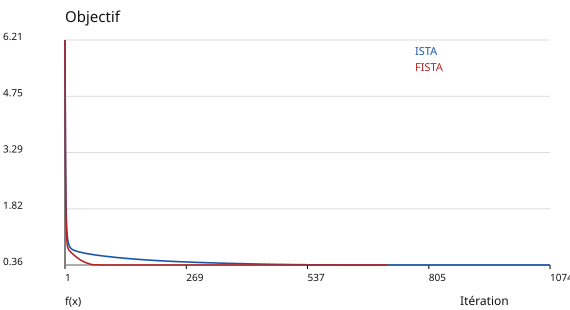

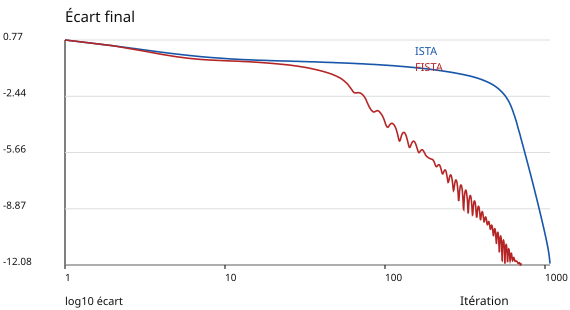

In [9]:
// Émet deux panneaux SVG opaques sous le MIME reconnu par GitHub.
record GraphSvg(string Value);
Formatter.Register<GraphSvg>((value, writer) => writer.Write(value.Value), "image/svg+xml");
string Plot(string title, string yLabel, (string label, double[] values, string color)[] series, bool logY = false, bool logX = false)
{
    const int width = 570, height = 310, left = 65, right = 20, top = 40, bottom = 45;
    var all = series.SelectMany(s => s.values).Where(v => double.IsFinite(v) && (!logY || v > 0)).Select(v => logY ? Math.Log10(v) : v).ToArray();
    double ymin = all.Min(), ymax = all.Max();
    if (ymax <= ymin) ymax = ymin + 1;
    int count = series.Max(s => s.values.Length);
    var svg = new StringBuilder($"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif' fill='#111'><text x='65' y='22' font-size='15'>{title}</text><text x='460' y='305' font-size='12'>Itération</text><text x='65' y='305' font-size='11'>{yLabel}</text><line x1='{left}' y1='{top}' x2='{left}' y2='{height-bottom}' stroke='black'/><line x1='{left}' y1='{height-bottom}' x2='{width-right}' y2='{height-bottom}' stroke='black'/>");
    for (int tick = 0; tick <= 4; tick++)
    {
        double value = ymin + (ymax - ymin) * tick / 4;
        double y = height - bottom - (height - top - bottom) * tick / 4.0;
        svg.Append($"<text x='3' y='{y:0.0}' font-size='10'>{value:0.##}</text><line x1='{left}' y1='{y:0.0}' x2='{width-right}' y2='{y:0.0}' stroke='#ddd'/>");
    }
    // Graduations en abscisse : réelles en linéaire, puissances de dix en logarithmique.
    if (logX)
    {
        for (int tick = 1; tick <= count; tick *= 10)
        {
            double x = left + (width-left-right) * Math.Log10(tick) / Math.Log10(Math.Max(2, count));
            svg.Append($"<line x1='{x:0.0}' y1='{height-bottom}' x2='{x:0.0}' y2='{height-bottom+4}' stroke='black'/><text x='{x:0.0}' y='{height-bottom+16}' font-size='10'>{tick}</text>");
            if (tick > count / 10) break;
        }
    }
    else
    {
        for (int tick = 0; tick <= 4; tick++)
        {
            double x = left + (width-left-right) * tick / 4.0;
            int iteration = 1 + (count-1) * tick / 4;
            svg.Append($"<line x1='{x:0.0}' y1='{height-bottom}' x2='{x:0.0}' y2='{height-bottom+4}' stroke='black'/><text x='{x:0.0}' y='{height-bottom+16}' font-size='10'>{iteration}</text>");
        }
    }
    int legend = 0;
    foreach (var item in series)
    {
        var points = new StringBuilder();
        for (int i = 0; i < item.values.Length; i++)
        {
            if (!double.IsFinite(item.values[i]) || (logY && item.values[i] <= 0))
            {
                if (points.Length > 0)
                {
                    svg.Append($"<polyline fill='none' stroke='{item.color}' stroke-width='1.6' points='{points}'/>");
                    points.Clear();
                }
                continue;
            }
            double value = logY ? Math.Log10(item.values[i]) : item.values[i];
            double position = logX ? Math.Log10(i + 1) / Math.Log10(Math.Max(2, count)) : i / (double)Math.Max(1, count-1);
            double px = left + (width-left-right) * position;
            double py = height-bottom - (height-top-bottom) * (value-ymin)/(ymax-ymin);
            points.Append($"{px:0.0},{py:0.0} ");
        }
        svg.Append($"<polyline fill='none' stroke='{item.color}' stroke-width='1.6' points='{points}'/><text x='{width-155}' y='{55+legend*16}' fill='{item.color}' font-size='11'>{item.label}</text>");
        legend++;
    }
    svg.Append("</g></svg>");
    return svg.ToString();
}
var gapIsta = ista.history.Select(v => v - ista.history.Last() + 1e-12).ToArray();
var gapFista = fista.history.Select(v => v - fista.history.Last() + 1e-12).ToArray();
display(new GraphSvg(Plot("Objectif", "f(x)", new[]{("ISTA",ista.history,"#1756a9"),("FISTA",fista.history,"#b52525")})), "image/svg+xml");
display(new GraphSvg(Plot("Écart final", "log10 écart", new[]{("ISTA",gapIsta,"#1756a9"),("FISTA",gapFista,"#b52525")},true,true)), "image/svg+xml");

### Exercice 3 — FISTA elastic net

Résoudre `½‖Ax−b‖² + λ₁‖x‖₁ + (λ₂/2)‖x‖²` par FISTA. Le gradient lisse devient `Aᵀ(Ax−b)+λ₂x`, sa constante `‖A‖²₂+λ₂` et le seuil proximal `λ₁/L`. Partir de zéro, exécuter jusqu'à 300 itérations et rendre le vecteur et l'historique de l'objectif **incluant** les deux pénalités. Le garde teste plusieurs matrices et la cohérence numérique de la trajectoire, sans certifier à lui seul la méthode utilisée.

In [10]:
(Vector<double> x, double[] history) ExerciceElasticNet(Matrix<double> matrix, Vector<double> target, double lam1, double lam2, int maxIter)
{
    // TODO : FISTA avec gradient Aᵀ(Ax-b)+lam2*x et seuil lam1/L.
    return (null, null);
}
// Valeurs de référence numériques : vecteurs finaux et trois premiers objectifs.
var expectedX=new[] { V.DenseOfArray(new[]{1.6666666666666665,-1.6666666666666667}), V.DenseOfArray(new[]{1.0486448922863096,-.1313412091730368}) };
var expectedFirst=new[] { new[]{5.092592592592593,4.578189300411522,4.301663052053922}, new[]{2.058684052159378,1.765581740419323,1.6425232544114523} };
var cases=new[]
{
    (Mat.DenseOfArray(new double[,] {{2,0},{0,1}}),V.DenseOfArray(new[]{4.0,-3.0}),.5,.5),
    (Mat.DenseOfArray(new double[,] {{1,1},{1,0},{0,2}}),V.DenseOfArray(new[]{2.0,1.0,-1.0}),.3,.7)
};
var answers=cases.Select(f=>ExerciceElasticNet(f.Item1,f.Item2,f.Item3,f.Item4,300)).ToArray();
if(answers.All(a=>a.x==null && a.history==null))
{
    Console.WriteLine("Exercice 3 à compléter.");
}
else if(answers.Any(a=>a.x==null || a.history==null))
{
    Console.WriteLine("Exercice 3 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<cases.Length;i++)
    {
        var (matrix,target,lam1,lam2)=cases[i];
        var (x,history)=answers[i];
        bool valid=x.Count==matrix.ColumnCount && history.Length>=3 && history.Length<=300 &&
                   x.All(double.IsFinite) && history.All(double.IsFinite);
        if(valid)
        {
            double objective=Objective(matrix,target,x,lam1)+.5*lam2*x.DotProduct(x);
            valid=(x-expectedX[i]).L2Norm()<1e-4 && Math.Abs(history.Last()-objective)<1e-8 &&
                  history.Take(3).Zip(expectedFirst[i],(a,b)=>Math.Abs(a-b)<1e-8).All(v=>v);
            // Rejouer plusieurs budgets pour vérifier les objectifs de leurs itérés effectifs.
            foreach(int k in new[]{0,1,2,4,9,history.Length-1}.Where(v=>v<history.Length).Distinct().OrderBy(v=>v))
            {
                var prefix=ExerciceElasticNet(matrix,target,lam1,lam2,k+1);
                if(prefix.x==null || prefix.history==null || prefix.x.Count!=matrix.ColumnCount || prefix.history.Length!=k+1)
                {
                    valid=false;
                    break;
                }
                double value=Objective(matrix,target,prefix.x,lam1)+.5*lam2*prefix.x.DotProduct(prefix.x);
                valid=valid && double.IsFinite(value) && Math.Abs(prefix.history.Last()-history[k])<1e-8 && Math.Abs(value-history[k])<1e-8;
            }
        }
        ok=ok && valid;
    }
    Console.WriteLine(ok ? "Exercice 3 : correct" : "Exercice 3 : à revoir");
}

Exercice 3 à compléter.


## 6. Synthèse et limites

| Méthode | Mécanisme | Éléments comparés |
|---|---|---|
| ISTA | gradient puis proximal L1 | objectif, support et nombre d'itérations |
| FISTA | même proximal avec inertie | mêmes données, pas et critère d'arrêt |
| sklearn Lasso | descente de coordonnées | même objectif via `α=λ/n` |
| CVXPY / CLARABEL | formulation convexe résolue numériquement | objectif et coefficients à tolérance près |

Sur le tirage affiché, l'erreur absolue et le rappel des quatre méthodes sont proches. Le compte au seuil `10⁻⁶` distingue les sorties : les sorties affichées ici donnent 91 composantes pour ISTA/FISTA/sklearn et 93 pour CLARABEL, avec des précisions différentes. Il faut examiner les valeurs et intersections réelles avant de conclure à une inclusion de supports. L'erreur à `x*` mélange bruit, pénalisation et précision de résolution ; elle n'est pas exclusivement le « biais de λ ».

Les méthodes de premier ordre ont des garanties sous-linéaires en objectif et peuvent être coûteuses à haute précision. Un pas global `1/L` peut être conservateur ; le backtracking explore un pas local. La descente de coordonnées et un solveur conique utilisent d'autres mécanismes et coûts : les temps affichés sont propres à cette exécution.

### Résultats de l'exécution affichée

| Solveur | Erreur absolue | Précision | Rappel | Nombre au seuil 10⁻⁶ |
|---|---:|---:|---:|---:|
| ISTA | 0,1316 | 0,308 | 0,933 | 91 |
| FISTA | 0,1316 | 0,308 | 0,933 | 91 |
| sklearn Lasso | 0,1316 | 0,308 | 0,933 | 91 |
| CVXPY / CLARABEL | 0,1316 | 0,301 | 0,933 | 93 |

Dans ces sorties, 28 des 30 positions vraies sont retrouvées : 28/91 et 28/93 expliquent les précisions. Le compte seul ne prouve pas l'inclusion des supports ; il dépend aussi des tolérances et du seuil de comptage.

## À retenir

1. Le seuillage doux met exactement à zéro les entrées dans la zone morte ; dans l'algorithme le seuil est `λ/L`.
2. ISTA fait un pas de gradient suivi du proximal ; FISTA extrapole **après** ce pas. Sous les hypothèses convexes et lisses usuelles, les bornes en écart d'objectif sont `O(1/k)` et `O(1/k²)` respectivement.
3. Les 200 mesures pour 500 inconnues ne certifient pas à elles seules la récupération du support ; `k log(p/k)` est une échelle heuristique.
4. `λ₀` puis son facteur cinq définissent cette expérience ; la normalisation de A et de la perte compte pour interpréter l'échelle.
5. Les méthodes visent le même problème ; leur accord arrondi, les supports seuillés et les coûts de calcul répondent à des questions différentes.

## Vérifiez votre compréhension

**1. Pourquoi le proximal L1 crée-t-il une zone morte ?**

<details><summary>Réponse</summary>La formule `sign(v) max(|v|−τ,0)` annule les composantes de module inférieur ou égal à τ et réduit les autres de τ sans changer leur signe.</details>

**2. Dans quel ordre FISTA utilise-t-il l'inertie ?**

<details><summary>Réponse</summary>Il calcule d'abord `x_next=prox(y−∇f(y)/L)`, puis `t_next` et `y_next=x_next+((t−1)/t_next)(x_next−x)`. Les taux en objectif exigent les hypothèses convexes et lisses ; un temps mesuré n'est pas une borne théorique.</details>

**3. Que signifie le λ choisi dans cette expérience ?**

<details><summary>Réponse</summary>Il est cinq fois l'échelle calculée à partir de σ, n et p. La matrice normalisée et la perte brute empêchent d'en déduire une garantie de sélection. Le seuil du proximal est λ/L.</details>

**4. Pourquoi les supports comptés peuvent-ils différer ?**

<details><summary>Réponse</summary>Le comptage à 10⁻⁶ dépend des valeurs proches du seuil et des tolérances numériques. Les seules cardinalités ne prouvent pas que les ensembles sont emboîtés ; il faut comparer les indices et les coefficients.</details>

## Pour aller plus loin

Le [notebook Python versionné](2.11b-Proximal-Operators-From-Scratch.ipynb) donne les références bibliographiques et le détail des sorties ; [ADMM](2.11d-Optimisation-ADMM-From-Scratch.ipynb) propose une autre décomposition. Les références associées par la source aux méthodes proximales comprennent Beck–Teboulle (FISTA), Parikh–Boyd (proximal), et la documentation de scikit-learn/CVXPY.

### Références associées par la source

- Beck, A., & Teboulle, M. (2009). *A fast iterative shrinkage-thresholding algorithm for linear inverse problems*. SIAM Journal on Imaging Sciences, 2(1), 183–202.
- Parikh, N., & Boyd, S. (2014). *Proximal algorithms*. Foundations and Trends in Optimization, 1(3), 127–239.
- Donoho, D. L. (2006). *Compressed sensing*. IEEE Transactions on Information Theory, 52(4), 1289–1306.
- Candès, E. J., Romberg, J., & Tao, T. (2006). *Robust uncertainty principles*. IEEE Transactions on Information Theory, 52(2), 489–509.

Ces références sont reprises du carnet Python versionné ; l'applicabilité de leurs hypothèses au tirage présenté n'est pas supposée.